170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2761s 16us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 183s 144ms/step - accuracy: 0.4193 - loss: 1.6287 - val_accuracy: 0.4783 - val_loss: 1.4843
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 179s 143ms/step - accuracy: 0.4862 - loss: 1.4479 - val_accuracy: 0.5003 - val_loss: 1.4322
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 207s 147ms/step - accuracy: 0.5044 - loss: 1.3946 - val_accuracy: 0.5017 - val_loss: 1.4174
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 176s 141ms/step - accuracy: 0.5162 - loss: 1.3655 - val_accuracy: 0.4988 - val_loss: 1.4123
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 195s 135ms/step - accuracy: 0.5244 - loss: 1.3432 - val_accuracy: 0.5072 - val_loss: 1.3889
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - accuracy: 0.5080 - loss: 1.3900
Test Accuracy: 50.80000162124634 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 698ms/step
Actual: cat
Predicted: cat
Training Accuracy: 52.43750214576721 %
Validation 

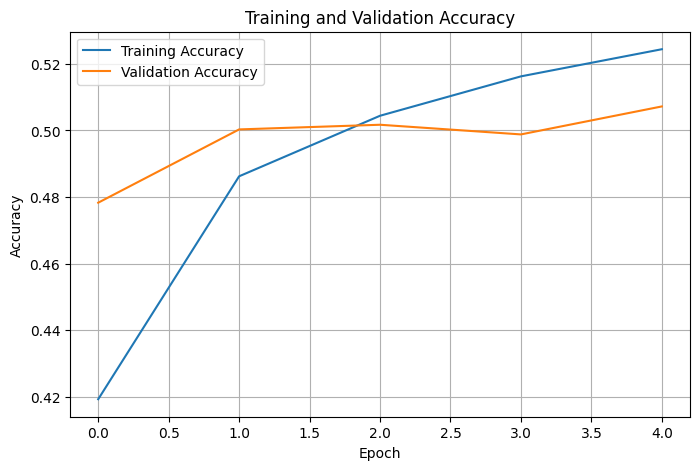

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Convert labels to 1D
y_train = y_train.flatten()
y_test = y_test.flatten()

# 2. Resize images
x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))

# 3. Load pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pre-trained layers
base_model.trainable = False

# 4. Create model
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 5. Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Train
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

# 7. Test model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")

# 8. Predict one image
prediction = model.predict(x_test[:1])

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

predicted_class = np.argmax(prediction)

print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])

# Print final training and validation accuracy
train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]

print("Training Accuracy:", train_accuracy * 100, "%")
print("Validation Accuracy:", val_accuracy * 100, "%")

# Test accuracy
loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy * 100, "%")


# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()